# Task 1. 1D Gaussian PF-ODE Trajectories

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import matplotlib.colors as colors

# Parameters
c = 10
T = 80
n_time_points = 200
n_x_points = 300
n_trajectories = 100 

# (A) Density
# --------------------------------------------------------
# Create grid for heatmap
# (A) Density

t_grid = np.linspace(0, T, n_time_points)

x_grid = np.linspace(
    -4*np.sqrt(c**2 + T**2),
    4*np.sqrt(c**2 + T**2),
    n_x_points
)

T_mesh, X_mesh = np.meshgrid(t_grid, x_grid)

density = stats.norm.pdf(
    X_mesh,
    loc=0,
    scale=np.sqrt(c**2 + T_mesh**2)
)


# (B) Trajectories

np.random.seed(42)

x_T_distribution = stats.norm(
    loc=0,
    scale=np.sqrt(c**2 + T**2)
)

x_T_samples = x_T_distribution.rvs(size=n_trajectories)

t_traj = np.linspace(T, 0, 200)


def backward_trajectory(x_T, t, T, c):
    traj = []

    for t_i in t:
        x_t = x_T * (c**2 + t_i**2) / (c**2 + T**2)
        traj.append(x_t)

    return traj


trajectories = np.array([
    backward_trajectory(x_T, t_traj, T, c)
    for x_T in x_T_samples
])

#### Visualize densities and trajectories

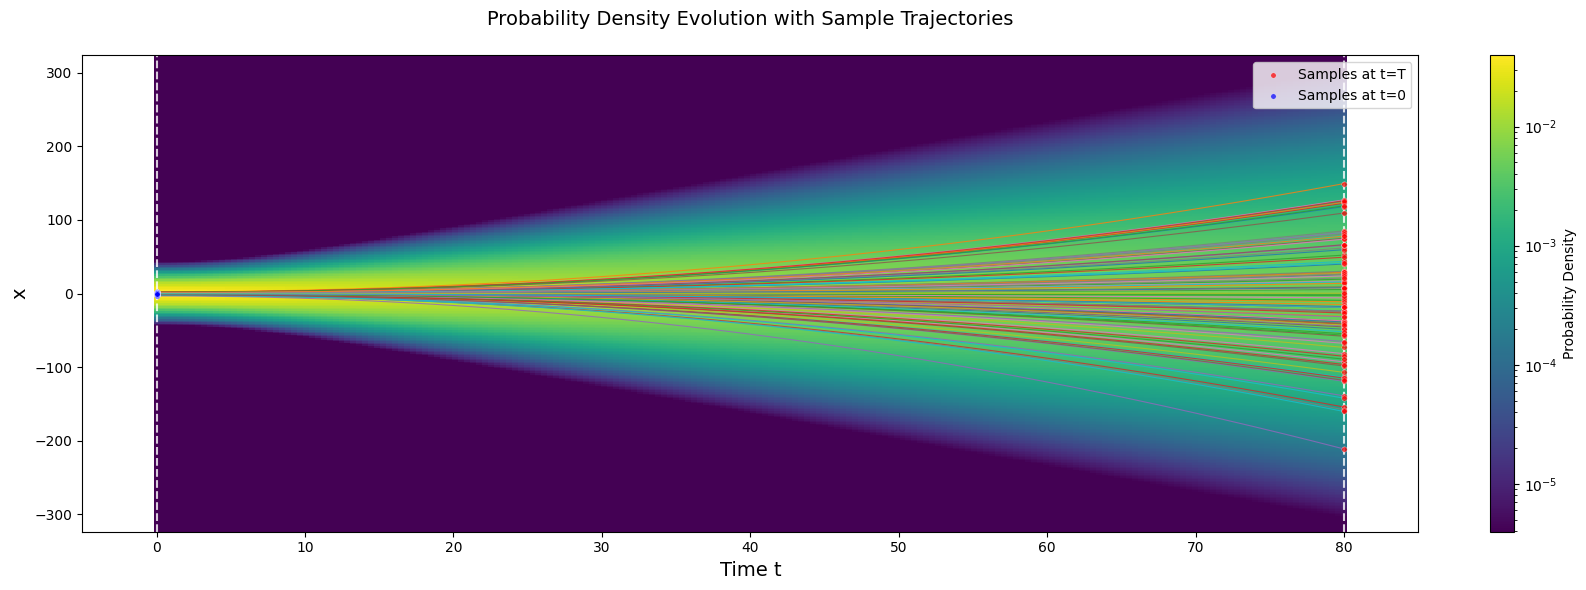

In [2]:
# Create the plot
plt.figure(figsize=(16, 6))

# Plot heatmap
im = plt.pcolormesh(t_grid, x_grid, density, shading='auto', cmap='viridis', 
                    norm=colors.LogNorm(vmin=density.max()/10000, vmax=density.max()))
plt.colorbar(im, label='Probability Density', fraction=0.02)

# Plot trajectories
for i, trajectory in enumerate(trajectories):
    plt.plot(t_traj, trajectory,
             alpha=0.8, linewidth=0.8, zorder=3)

# Mark start and end points with distinct markers
plt.scatter([T]*n_trajectories, x_T_samples, color='red', s=15, zorder=4, 
            label=f'Samples at t=T', alpha=0.7, edgecolors='white', linewidth=0.3)
plt.scatter([0]*n_trajectories, trajectories[:, -1], color='blue', s=15, zorder=4, 
            label=f'Samples at t=0', alpha=0.7, edgecolors='white', linewidth=0.3)

# 3rd party
plt.axvline(x=0, color='white', linestyle='--', alpha=0.8, linewidth=1.5)
plt.axvline(x=T, color='white', linestyle='--', alpha=0.8, linewidth=1.5)
plt.xlabel('Time t', fontsize=14)
plt.ylabel('x', fontsize=14)
plt.title(f'Probability Density Evolution with Sample Trajectories\n', 
          fontsize=14)
plt.legend(loc='upper right', fontsize=10)
plt.xlim(-5, T+5)
plt.tight_layout()
plt.show()

# Task 2. Ideal denoiser

In [ ]:
import torch
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt

# Load CIFAR10
tfm = T.Compose([
    T.ToTensor(), 
    T.Normalize(
        (0.5, 0.5, 0.5), 
        (0.5, 0.5, 0.5)
    )
])
ds = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=tfm)

#### Implement class-unconditional ideal denoiser

In [ ]:
def ideal_denoiser(x, Y, sigma):
    # YOUR CODE

Y = # YOUR CODE

#### Visualize its predictions for different sigmas

In [ ]:
class_names = ds.classes
sigmas = [0, 0.2, 0.5, 1, 2, 3, 4, 5, 7, 10, 20, 50]

img_idxs = torch.randint(
    0, len(ds), size=(10,), 
    generator=torch.Generator().manual_seed(1)
) # <-- !!! use this for final submission !!!

for img_idx in img_idxs:
    img, cls = ds[img_idx]
    
    plt.figure(figsize=(20, 3))
    plt.suptitle(f"Class {cls}: {class_names[cls]}", fontsize=16, y=0.85)

    for i, s in enumerate(sigmas):
        generator = torch.Generator().manual_seed(0)

        # Apply noise 
        x_sigma = # YOUR CODE HERE (use generator)

        out = ideal_denoiser(x_sigma, Y, s)

        show = (out[0] + 1) / 2 
        plt.subplot(1, len(sigmas), i+1)
        plt.title(f"σ={s}", fontsize=10)
        plt.imshow(show.permute(1,2,0))
        plt.axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.90])
    plt.show()

#### Make the ideal denoiser class-conditional and visualize its predictions

In [ ]:
# YOUR CODE

### Explain the ideal denoiser's behavior and compare conditional vs unconditional denoisers

---------------
YOUR CONCLUSION